## **Expiry-Day Liquidity Concentration in Indian Index Derivatives**

### **Notebook: 10: Option Microstructure, Placebo and Dose-Response**

---

**Scope:** Contract-level index-option outcomes (days-to-expiry mix, far-OTM share, exploratory ATM high-low measures), the never-weekly stock-F&O placebo and the daily dose-response around the Nov-2024 transition. Reproduce: `python -m scripts.build_option_contract_panel` (~5 min), `python -m scripts.option_microstructure_did`.

---

### Pipeline sequence

1. **01_data_collection.ipynb** -- index OHLCV, F&O Bhavcopy archive (NOTE: the rule-based expiry calendar it builds is NOT used for inference)
2. **02_feature_engineering_and_fo_construction.ipynb** -- technical features (true-calendar expiry features) and the true-expiry index panel
3. **03_weekly_options_discontinuation_identification.ipynb** -- true expiry dates per index and a calendar audit
4. **04_primary_diff_in_diff_analysis.ipynb** -- corrected symbol-month DiD (turnover, expiry-day turnover, expiry-day share)
5. **05_robustness_checks.ipynb** -- placebo, window sensitivity, substitution range, participant mix, futures market quality
6. **06_expiry_volume_event_study.ipynb** -- expiry-day concentration for six NSE/BSE indices
7. **07_walk_forward_predictability.ipynb** -- secondary: leakage-free predictability test on the true calendar (null)
8. **08_interrupted_time_series.ipynb** -- secondary: settlement-weekday ITS plus clean weekday-only contrasts (null)
9. **09_figures.ipynb** -- displays the corrected figures
10. **10_option_microstructure_and_placebo.ipynb** -- option-level outcomes, stock-F&O placebo, dose-response

**Current location:** **10_option_microstructure_and_placebo.ipynb** <- *you are here*


In [1]:
import sys
from pathlib import Path

project_dir = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

import pandas as pd
import json
from src import config

pd.set_option('display.max_columns', 20)
print('Project root:', project_dir)

Project root: E:\Research-IPR\Research_BN_N50\banknifty-expiry-volatility-ml


### 1. Placebo and dose-response
Stock F&O never had weeklies: if the collapse were a market-wide shock (margins, lot sizes, taxes) it would show there too. The dose-response regresses the daily Bank Nifty-vs-Nifty log turnover gap on the number of Bank Nifty option expiries listed while the weeklies rolled off.

In [2]:
r = json.load(open(config.RESULTS_DIR / 'option_microstructure_did.json'))
print(json.dumps({k: r[k] for k in ['stock_placebo', 'dose_response']}, indent=1))

{
 "stock_placebo": {
  "stock_fo_post_over_pre": 0.9104760169914318,
  "BANKEX_post_over_pre": 0.028376726365378052,
  "BANKNIFTY_post_over_pre": 0.0992287924713631,
  "FINNIFTY_post_over_pre": 0.009880353276539708,
  "MIDCPNIFTY_post_over_pre": 0.053023225317198254,
  "NIFTY_post_over_pre": 1.665995038298127,
  "SENSEX_post_over_pre": 2.5390789954806174
 },
 "dose_response": {
  "coef_per_listed_expiry": 0.3587369175556486,
  "se": 0.07440880052224988,
  "p": 1.4272404242586838e-06,
  "n": 83
 }
}


### 2. Contract-level outcomes
`dte01_share` and `dte07_share` are turnover shares in contracts within 1 / 7 days of expiry; `otm5_share` is the share in options more than 5% out of the money. `atm_cs` and `atm_hl` are exploratory: Corwin-Schultz spreads of 14-22% for options mostly reflect volatility and price level, so do NOT read them as market quality.

In [3]:
within = {k: {o: (round(v['coef'], 3), round(v['p'], 3)) for o, v in r[k].items()} for k in r if ': ' in k}
print(pd.DataFrame(within).T)
print(pd.DataFrame(r['pooled_twfe']).T)
pd.concat({s: pd.DataFrame(v).T for s, v in r['descriptives'].items()}).round(3)

                            dte01_share      dte07_share    otm5_share  \
NSE: BANKNIFTY vs NIFTY   (-0.219, 0.0)    (-0.343, 0.0)  (0.072, 0.0)   
BSE: BANKEX vs SENSEX    (0.066, 0.129)  (-0.005, 0.002)  (-0.02, 0.0)   

                                  atm_cs           atm_hl  
NSE: BANKNIFTY vs NIFTY  (-0.062, 0.033)    (-0.393, 0.0)  
BSE: BANKEX vs SENSEX    (-0.057, 0.249)  (-0.522, 0.001)  
                 coef  randomization_p
dte01_share -0.074086         0.466667
dte07_share -0.151544         0.133333
otm5_share   0.017489         0.466667
atm_cs      -0.065247         0.066667
atm_hl      -0.437147         0.066667


dte01_share  dte07_share  otm5_share  atm_cs  atm_hl
BANKEX     pre         0.931        1.000       0.003   0.191   1.349
           post        0.979        0.994       0.006   0.143   0.805
BANKNIFTY  pre         0.732        0.984       0.058   0.197   0.961
           post        0.542        0.714       0.104   0.138   0.664
FINNIFTY   pre         0.904        0.999       0.021   0.222   1.158
           post        0.761        0.893       0.042   0.125   0.734
MIDCPNIFTY pre         0.873        0.999       0.015   0.225   1.329
           post        0.580        0.775       0.081   0.155   0.784
NIFTY      pre         0.703        0.968       0.039   0.166   0.911
           post        0.662        0.969       0.052   0.163   0.927
SENSEX     pre         0.982        1.000       0.002   0.171   1.017
           post        0.883        0.998       0.022   0.168   0.967

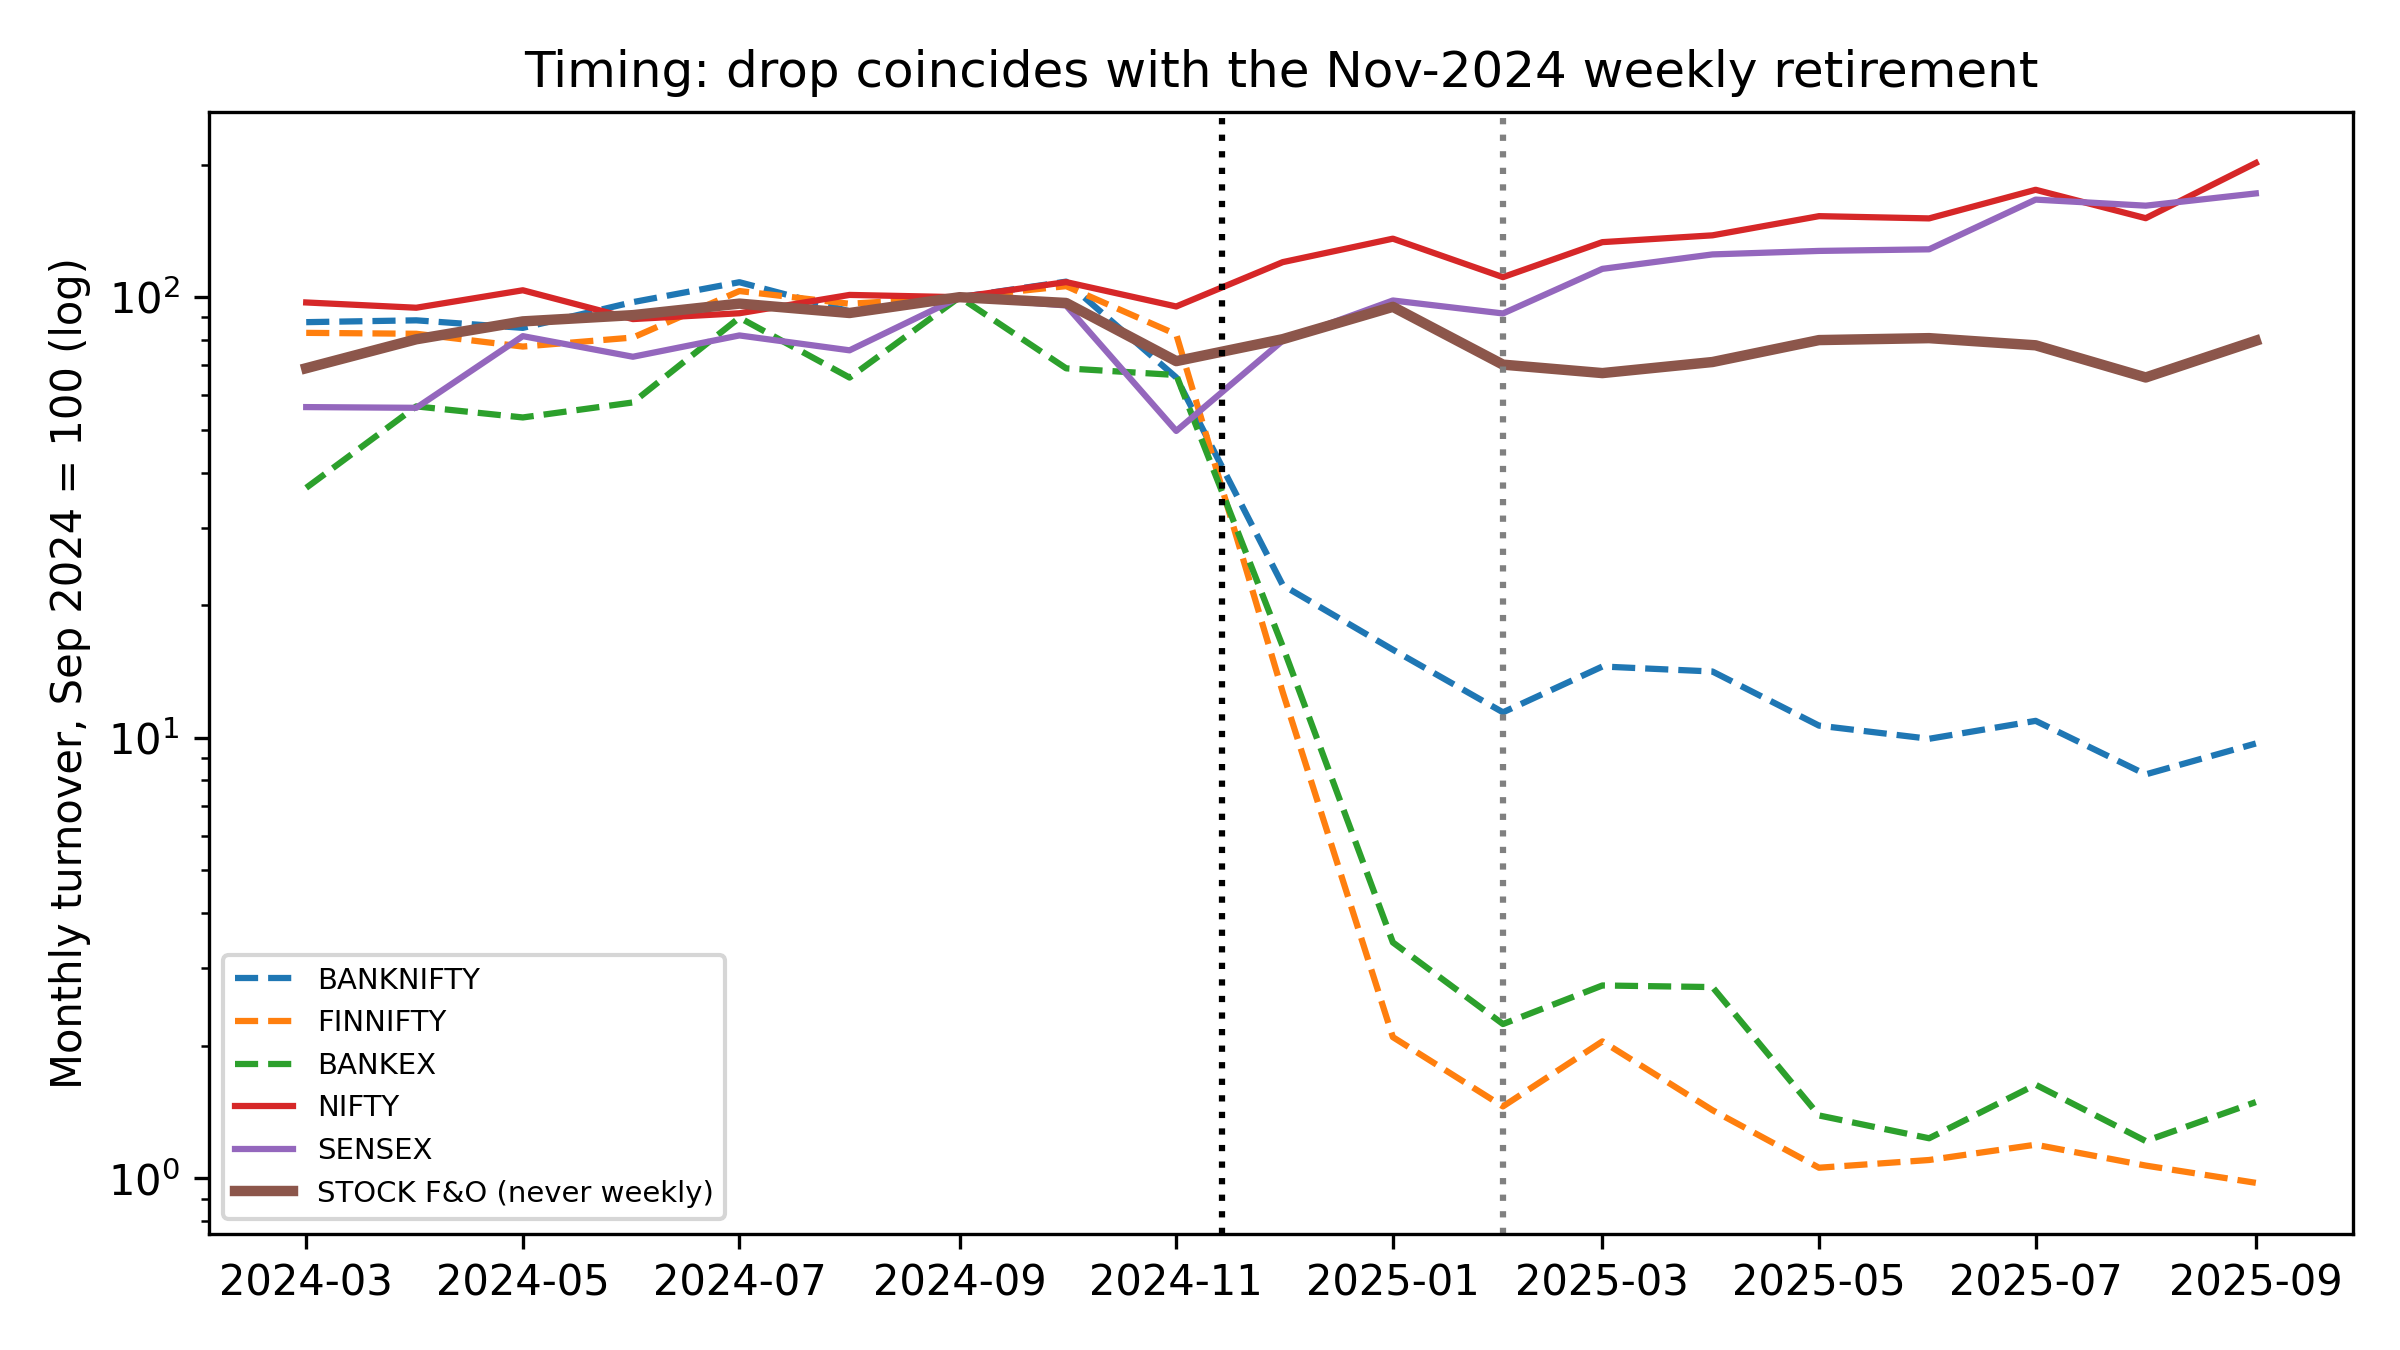

In [4]:
from IPython.display import Image, display
display(Image(filename=str(config.FIGURES_DIR / 'fig6_timing_and_stock_placebo.png')))